# **Dataset 2 (APCEM implemented original one) with denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 10, 10, 7, 21)** 

Using compute device: cuda
Discovered 2634 raw images across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Applying APCEM and extracting nucleus masks for 'train' split (1843 images)...
Applying APCEM and extracting nucleus masks for 'val' split (395 images)...
Applying APCEM and extracting nucleus masks for 'test' split (396 images)...

APCEM preprocessing and nucleus mask extraction complete.

Starting joint training on Cytology Dataset 2 (Raw with APCEM)...
Epoch 01/50 | Train Loss: 2.3579 Acc: 0.476 Dice: 0.267 | Val Loss: 2.2643 Acc: 0.499 Dice: 0.307
Epoch 02/50 | Train Loss: 2.0209 Acc: 0.515 Dice: 0.295 | Val Loss: 2.2267 Acc: 0.466 Dice: 0.305
Epoch 03/50 | Train Loss: 1.8520 Acc: 0.563 Dice: 0.308 | Val Loss: 1.9369 Acc: 0.519 Dice: 0.251
Epoch 04/50 | Train Loss: 1.8058 Acc: 0.571 Dice: 0.310 | Val Loss: 2.0556 Acc: 0.522 Dice: 0.297
Epoch 05/50 | Train Loss: 1.7894 Acc: 0.575 Dice: 0.326 | Val Loss: 10.2196 Acc: 0.263 Dice: 0.341
Epoch 06/50 | Train Loss: 1.726

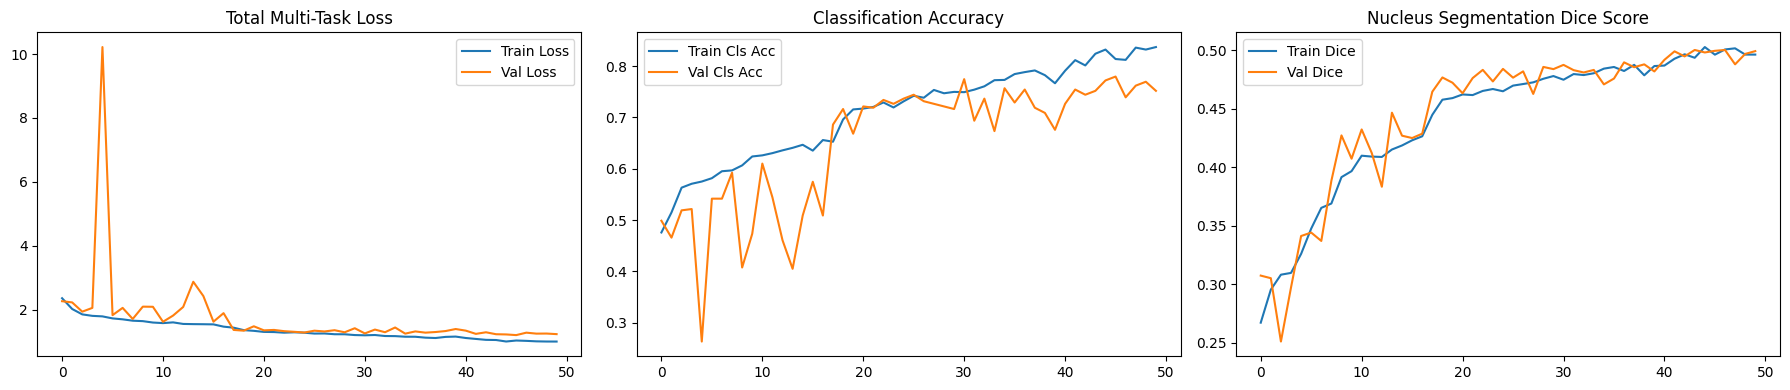


Final Test Classification Accuracy: 0.7879
Final Test Nucleus Segmentation Mean Dice Score: 0.4837

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.56      0.63      0.59        30
        HSIL       0.75      0.76      0.75       127
        LSIL       0.73      0.68      0.71        92
        NILM       0.99      0.99      0.99        92
         SCC       0.78      0.76      0.77        55

    accuracy                           0.79       396
   macro avg       0.76      0.77      0.76       396
weighted avg       0.79      0.79      0.79       396



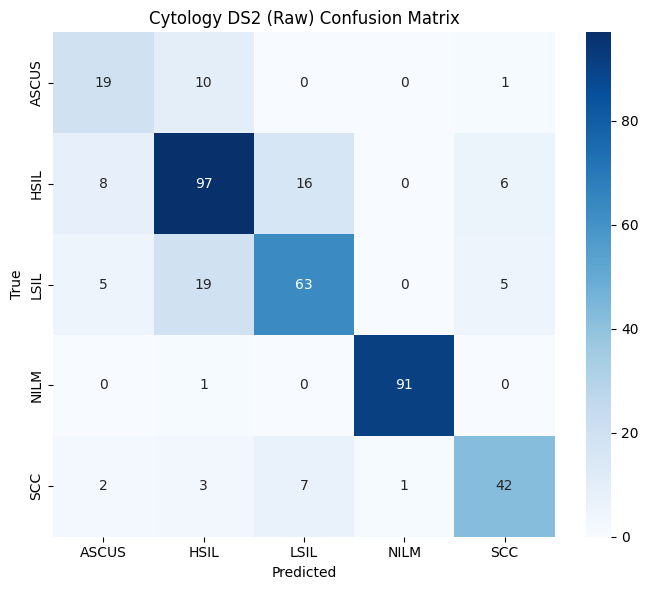

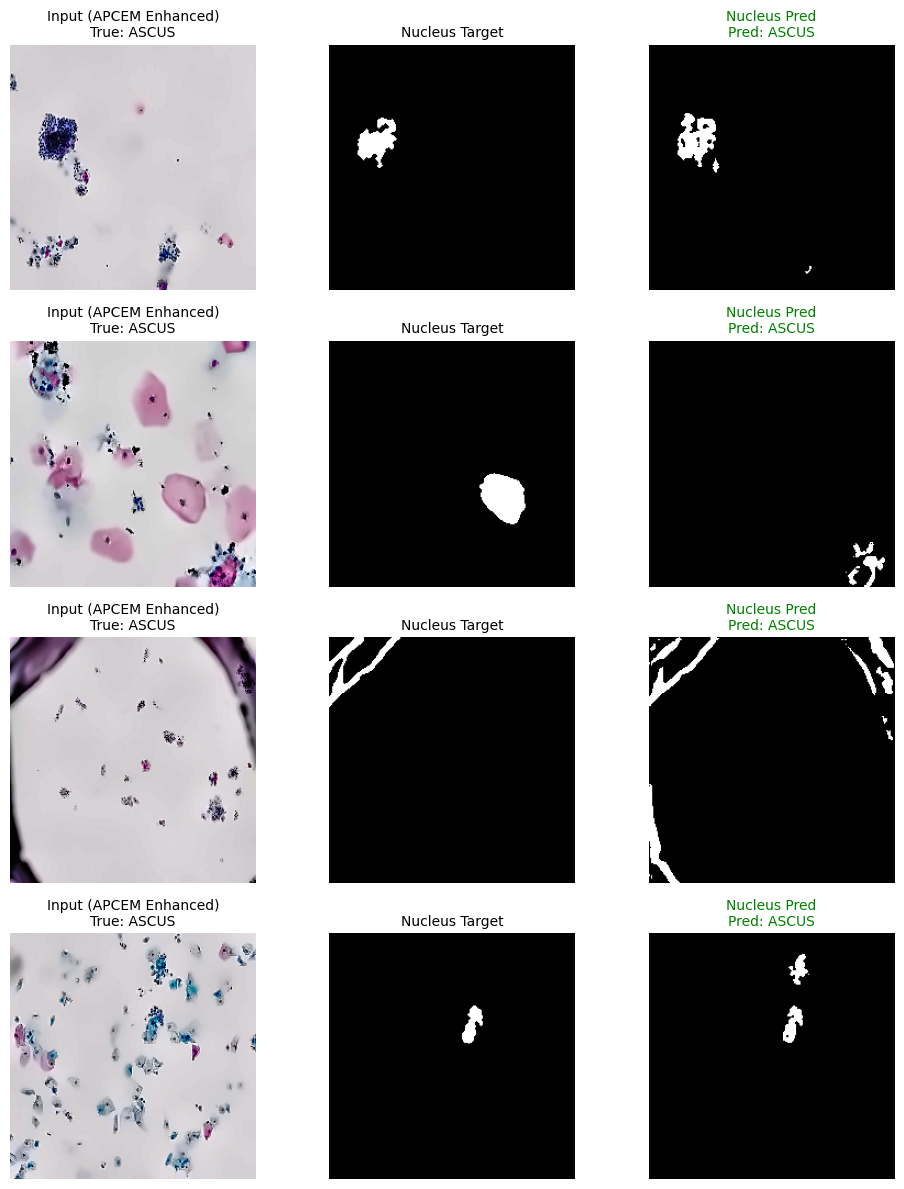

In [1]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_ds2_raw_multitask_data"
PLOTS_DIR = "plots_cytology_ds2_raw"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Images)
# ---------------------------------------------------------

def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, non-local means denoising, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Edge-preserving noise reduction using non-local means filtering
    # h=10, hColor=10 are standard parameters for mild noise reduction
    # 7 is the template window size, 21 is the search window size
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 10, 10, 7, 21)

    # 3. Controlled sharpening using unsharp masking to enhance boundaries
    blurred = cv2.GaussianBlur(denoised, (0, 0), 1.0)
    sharpened = cv2.addWeighted(denoised, 1.5, blurred, -0.5, 0)
    
    # Normalize back to [0.0, 1.0] range
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced



# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """
    Extracts high-contrast nucleus masks from APCEM-enhanced images
    via adaptive thresholding and morphological filtering.
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Adaptive thresholding to segment dark, chromatin-rich nuclear regions
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    # Morphological filtering to isolate central nucleus
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    # Keep the largest central contour
    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Dataset Discovery, APCEM Processing & Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_DIR}")

all_records = []

for cls in BETHESDA_CLASSES:
    cls_dir = os.path.join(RAW_DATA_DIR, cls)
    if os.path.exists(cls_dir):
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
            for img_path in glob.glob(os.path.join(cls_dir, ext)):
                all_records.append((img_path, cls))

if len(all_records) == 0:
    raise RuntimeError(f"No images found in: {RAW_DATA_DIR}")

print(f"Discovered {len(all_records)} raw images across Bethesda classes: {BETHESDA_CLASSES}")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Applying APCEM and extracting nucleus masks for '{split_name}' split ({len(recs)} images)...")
    for idx, (img_path, cls_name) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        # Apply APCEM enhancement to raw image
        img_enhanced = apcem_preprocess(img_resized)
        img_enhanced_uint8 = (img_enhanced * 255.0).astype(np.uint8)

        # Extract nucleus mask from enhanced image
        mask = extract_nucleus_mask(img_enhanced_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_enhanced_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nAPCEM preprocessing and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Cytology Dataset 2 (Raw with APCEM)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_ds2_raw_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nOptimal model weights restored from validation checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Cytology DS2 (Raw) Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input (APCEM Enhanced)\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_sample_inference.png", dpi=200)
plt.show()

# **Dataset 2 (APCEM implemented original one) with denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 5, 5, 7, 21)**#

# Best Result

Using compute device: cuda
Discovered 2634 raw images across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Applying APCEM and extracting nucleus masks for 'train' split (1843 images)...
Applying APCEM and extracting nucleus masks for 'val' split (395 images)...
Applying APCEM and extracting nucleus masks for 'test' split (396 images)...

APCEM preprocessing and nucleus mask extraction complete.

Starting joint training on Cytology Dataset 2 (Raw with APCEM)...
Epoch 01/50 | Train Loss: 2.3508 Acc: 0.483 Dice: 0.266 | Val Loss: 2.6970 Acc: 0.423 Dice: 0.297
Epoch 02/50 | Train Loss: 2.0601 Acc: 0.527 Dice: 0.295 | Val Loss: 2.5780 Acc: 0.446 Dice: 0.268
Epoch 03/50 | Train Loss: 1.9065 Acc: 0.557 Dice: 0.301 | Val Loss: 1.9395 Acc: 0.537 Dice: 0.246
Epoch 04/50 | Train Loss: 1.8808 Acc: 0.552 Dice: 0.305 | Val Loss: 2.1461 Acc: 0.501 Dice: 0.306
Epoch 05/50 | Train Loss: 1.8305 Acc: 0.564 Dice: 0.315 | Val Loss: 2.9589 Acc: 0.478 Dice: 0.323
Epoch 06/50 | Train Loss: 1.7649

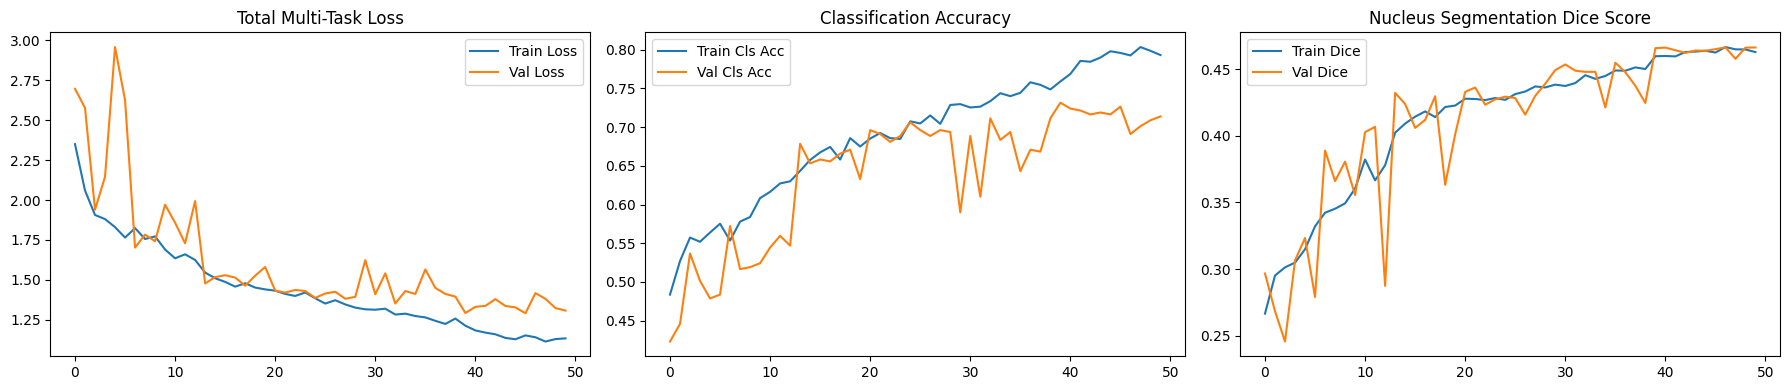


Final Test Classification Accuracy: 0.7399
Final Test Nucleus Segmentation Mean Dice Score: 0.4701

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.53      0.63      0.58        30
        HSIL       0.71      0.70      0.71       127
        LSIL       0.73      0.61      0.66        92
        NILM       0.98      0.99      0.98        92
         SCC       0.58      0.69      0.63        55

    accuracy                           0.74       396
   macro avg       0.71      0.72      0.71       396
weighted avg       0.75      0.74      0.74       396



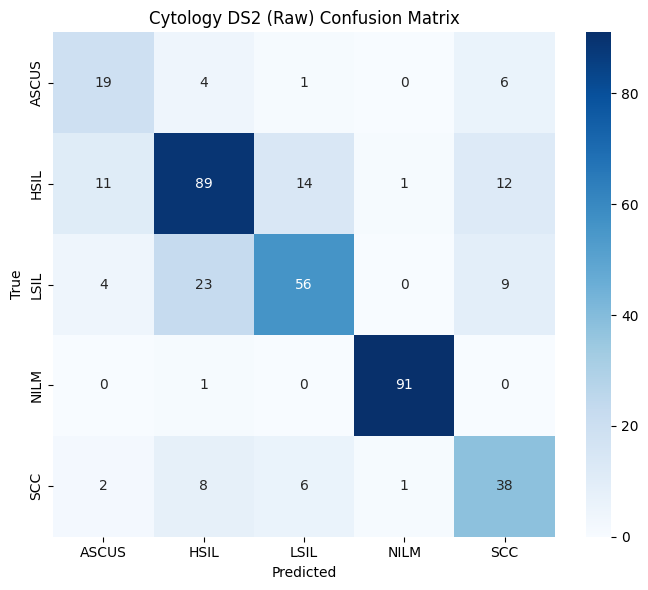

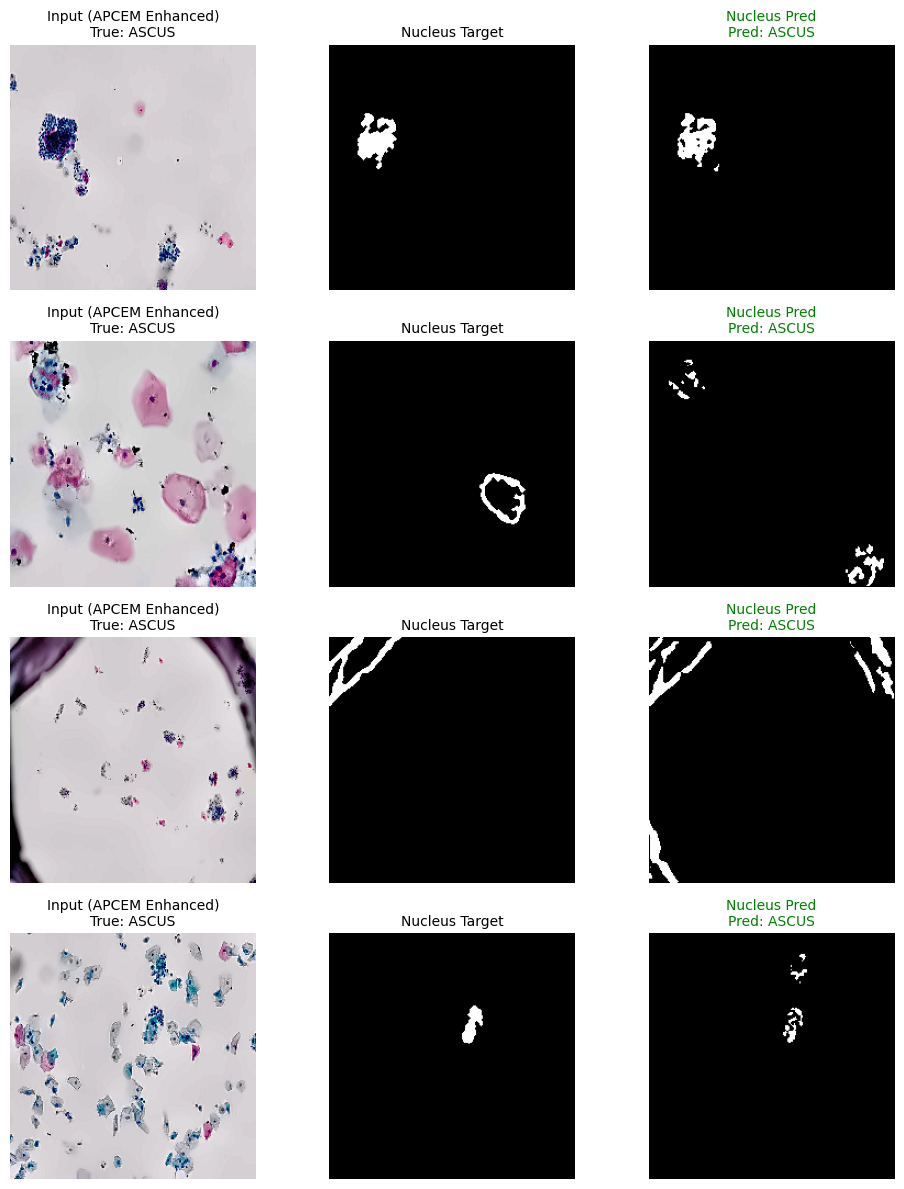

In [2]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_ds2_raw_multitask_data"
PLOTS_DIR = "plots_cytology_ds2_raw"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Images)
# ---------------------------------------------------------

def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, non-local means denoising, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Edge-preserving noise reduction using non-local means filtering
    # h=10, hColor=10 are standard parameters for mild noise reduction
    # 7 is the template window size, 21 is the search window size
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 5, 5, 7, 21)

    # 3. Controlled sharpening using unsharp masking to enhance boundaries
    blurred = cv2.GaussianBlur(denoised, (0, 0), 1.0)
    sharpened = cv2.addWeighted(denoised, 1.5, blurred, -0.5, 0)
    
    # Normalize back to [0.0, 1.0] range
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced



# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """
    Extracts high-contrast nucleus masks from APCEM-enhanced images
    via adaptive thresholding and morphological filtering.
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Adaptive thresholding to segment dark, chromatin-rich nuclear regions
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    # Morphological filtering to isolate central nucleus
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    # Keep the largest central contour
    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Dataset Discovery, APCEM Processing & Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_DIR}")

all_records = []

for cls in BETHESDA_CLASSES:
    cls_dir = os.path.join(RAW_DATA_DIR, cls)
    if os.path.exists(cls_dir):
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
            for img_path in glob.glob(os.path.join(cls_dir, ext)):
                all_records.append((img_path, cls))

if len(all_records) == 0:
    raise RuntimeError(f"No images found in: {RAW_DATA_DIR}")

print(f"Discovered {len(all_records)} raw images across Bethesda classes: {BETHESDA_CLASSES}")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Applying APCEM and extracting nucleus masks for '{split_name}' split ({len(recs)} images)...")
    for idx, (img_path, cls_name) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        # Apply APCEM enhancement to raw image
        img_enhanced = apcem_preprocess(img_resized)
        img_enhanced_uint8 = (img_enhanced * 255.0).astype(np.uint8)

        # Extract nucleus mask from enhanced image
        mask = extract_nucleus_mask(img_enhanced_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_enhanced_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nAPCEM preprocessing and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Cytology Dataset 2 (Raw with APCEM)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_ds2_raw_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nOptimal model weights restored from validation checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Cytology DS2 (Raw) Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input (APCEM Enhanced)\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_sample_inference.png", dpi=200)
plt.show()

In [3]:
# Install library
# !pip install torchinfo

from torchinfo import summary

model = MultiTaskCytologyNet(num_classes=5)
# Print layer breakdown for (3, 224, 224) input
summary(model, input_size=(1, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "kernel_size"])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
MultiTaskCytologyNet                     [1, 3, 224, 224]          [1, 1, 224, 224]          --                        --
├─DoubleConv: 1-1                        [1, 3, 224, 224]          [1, 32, 224, 224]         --                        --
│    └─Sequential: 2-1                   [1, 3, 224, 224]          [1, 32, 224, 224]         --                        --
│    │    └─Conv2d: 3-1                  [1, 3, 224, 224]          [1, 32, 224, 224]         864                       [3, 3]
│    │    └─BatchNorm2d: 3-2             [1, 32, 224, 224]         [1, 32, 224, 224]         64                        --
│    │    └─ReLU: 3-3                    [1, 32, 224, 224]         [1, 32, 224, 224]         --                        --
│    │    └─Conv2d: 3-4                  [1, 32, 224, 224]         [1, 32, 224, 224]         9,216                     [3, 3]
│    │

# **Dataset 2 (APCEM implemented original one) with denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 5, 7, 7, 21)**

Using compute device: cuda
Discovered 2634 raw images across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Applying APCEM and extracting nucleus masks for 'train' split (1843 images)...
Applying APCEM and extracting nucleus masks for 'val' split (395 images)...
Applying APCEM and extracting nucleus masks for 'test' split (396 images)...

APCEM preprocessing and nucleus mask extraction complete.

Starting joint training on Cytology Dataset 2 (Raw with APCEM)...
Epoch 01/50 | Train Loss: 2.3516 Acc: 0.493 Dice: 0.268 | Val Loss: 2.3582 Acc: 0.511 Dice: 0.312
Epoch 02/50 | Train Loss: 1.9964 Acc: 0.537 Dice: 0.296 | Val Loss: 1.9077 Acc: 0.575 Dice: 0.306
Epoch 03/50 | Train Loss: 1.8599 Acc: 0.563 Dice: 0.299 | Val Loss: 1.9498 Acc: 0.537 Dice: 0.291
Epoch 04/50 | Train Loss: 1.7952 Acc: 0.589 Dice: 0.313 | Val Loss: 4.1137 Acc: 0.327 Dice: 0.318
Epoch 05/50 | Train Loss: 1.8436 Acc: 0.563 Dice: 0.326 | Val Loss: 1.7494 Acc: 0.590 Dice: 0.318
Epoch 06/50 | Train Loss: 1.7333

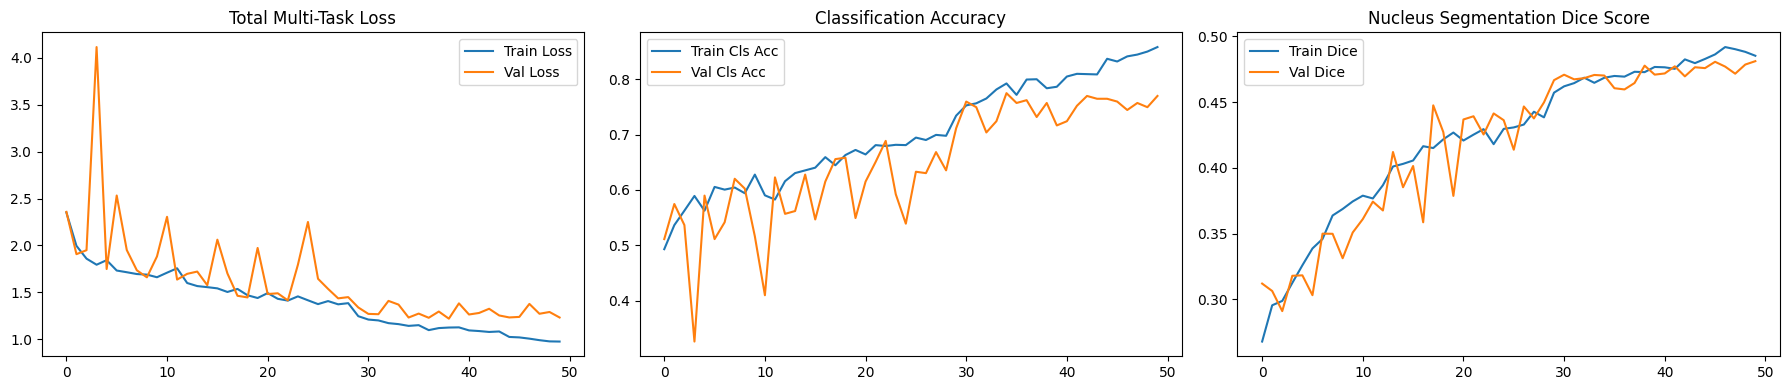


Final Test Classification Accuracy: 0.7980
Final Test Nucleus Segmentation Mean Dice Score: 0.4854

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.61      0.57      0.59        30
        HSIL       0.78      0.76      0.77       127
        LSIL       0.78      0.70      0.74        92
        NILM       0.99      0.98      0.98        92
         SCC       0.69      0.87      0.77        55

    accuracy                           0.80       396
   macro avg       0.77      0.78      0.77       396
weighted avg       0.80      0.80      0.80       396



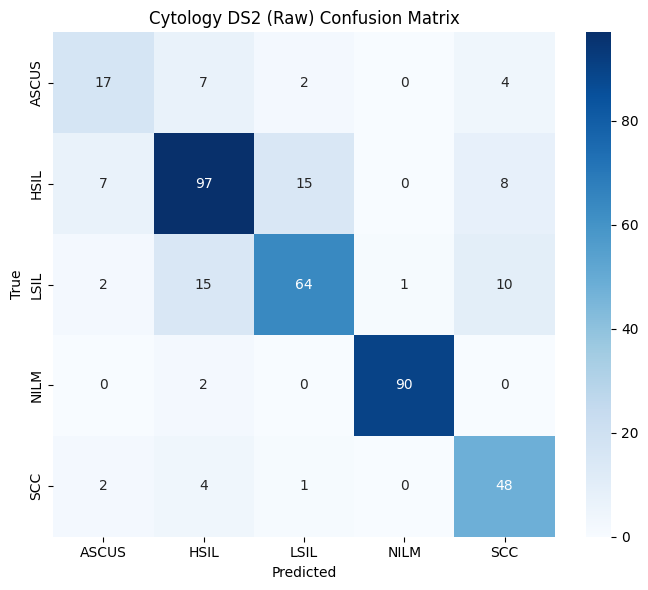

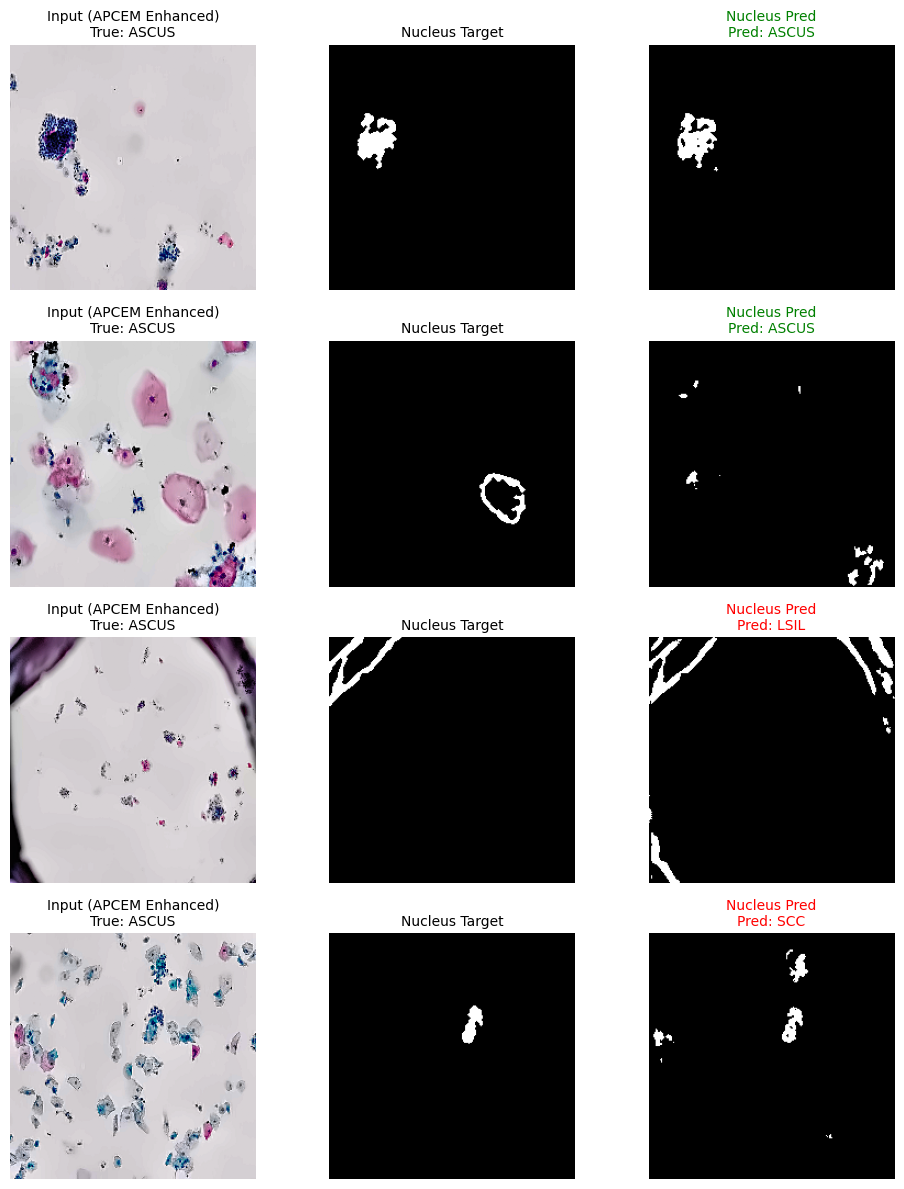

In [4]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_ds2_raw_multitask_data"
PLOTS_DIR = "plots_cytology_ds2_raw"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Images)
# ---------------------------------------------------------

def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, non-local means denoising, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Edge-preserving noise reduction using non-local means filtering
    # h=10, hColor=10 are standard parameters for mild noise reduction
    # 7 is the template window size, 21 is the search window size
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 5, 7, 7, 21)

    # 3. Controlled sharpening using unsharp masking to enhance boundaries
    blurred = cv2.GaussianBlur(denoised, (0, 0), 1.0)
    sharpened = cv2.addWeighted(denoised, 1.5, blurred, -0.5, 0)
    
    # Normalize back to [0.0, 1.0] range
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced



# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """
    Extracts high-contrast nucleus masks from APCEM-enhanced images
    via adaptive thresholding and morphological filtering.
    """
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Adaptive thresholding to segment dark, chromatin-rich nuclear regions
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    # Morphological filtering to isolate central nucleus
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    # Keep the largest central contour
    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Dataset Discovery, APCEM Processing & Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer/Image"

if not os.path.exists(RAW_DATA_DIR):
    raise FileNotFoundError(f"Dataset path not found: {RAW_DATA_DIR}")

all_records = []

for cls in BETHESDA_CLASSES:
    cls_dir = os.path.join(RAW_DATA_DIR, cls)
    if os.path.exists(cls_dir):
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
            for img_path in glob.glob(os.path.join(cls_dir, ext)):
                all_records.append((img_path, cls))

if len(all_records) == 0:
    raise RuntimeError(f"No images found in: {RAW_DATA_DIR}")

print(f"Discovered {len(all_records)} raw images across Bethesda classes: {BETHESDA_CLASSES}")

# Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Applying APCEM and extracting nucleus masks for '{split_name}' split ({len(recs)} images)...")
    for idx, (img_path, cls_name) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        # Apply APCEM enhancement to raw image
        img_enhanced = apcem_preprocess(img_resized)
        img_enhanced_uint8 = (img_enhanced * 255.0).astype(np.uint8)

        # Extract nucleus mask from enhanced image
        mask = extract_nucleus_mask(img_enhanced_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_enhanced_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nAPCEM preprocessing and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.rsplit("_", 1)[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits


# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Cytology Dataset 2 (Raw with APCEM)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_ds2_raw_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nOptimal model weights restored from validation checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Cytology DS2 (Raw) Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input (APCEM Enhanced)\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_ds2_raw_sample_inference.png", dpi=200)
plt.show()

# **Merged Cytology Dataset 1 + 2 (Using Model 2)**

Using compute device: cuda
Loaded 4134 pre-enhanced images from Dataset 1.
Loaded 0 raw images from Dataset 2.

Total merged records: 4134 across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Processing and saving 2893 samples for 'train' split...
Processing and saving 620 samples for 'val' split...
Processing and saving 621 samples for 'test' split...

Merged dataset preparation and nucleus mask extraction complete.

Starting joint training on Merged Cytology Dataset (1+2)...
Epoch 01/50 | Train Loss: 2.3053 Acc: 0.437 Dice: 0.276 | Val Loss: 2.0118 Acc: 0.434 Dice: 0.314
Epoch 02/50 | Train Loss: 2.0007 Acc: 0.482 Dice: 0.303 | Val Loss: 1.8398 Acc: 0.498 Dice: 0.325
Epoch 03/50 | Train Loss: 1.9158 Acc: 0.507 Dice: 0.325 | Val Loss: 1.7993 Acc: 0.552 Dice: 0.337
Epoch 04/50 | Train Loss: 1.8505 Acc: 0.522 Dice: 0.343 | Val Loss: 1.8029 Acc: 0.527 Dice: 0.368
Epoch 05/50 | Train Loss: 1.8222 Acc: 0.522 Dice: 0.361 | Val Loss: 1.7271 Acc: 0.618 Dice: 0.319
Epoch 06/50 | T

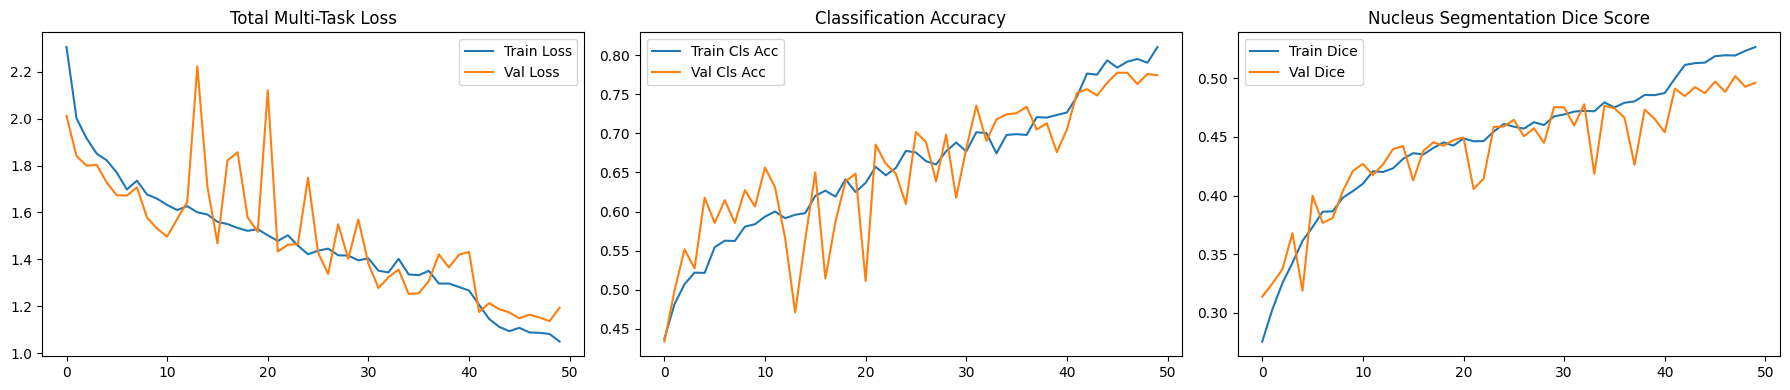


Final Test Classification Accuracy: 0.7939
Final Test Nucleus Segmentation Mean Dice Score: 0.4466

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.75      0.41      0.53        51
        HSIL       0.75      0.76      0.75       195
        LSIL       0.73      0.80      0.76       187
        NILM       0.98      0.96      0.97       117
         SCC       0.81      0.89      0.85        71

    accuracy                           0.79       621
   macro avg       0.80      0.76      0.77       621
weighted avg       0.79      0.79      0.79       621



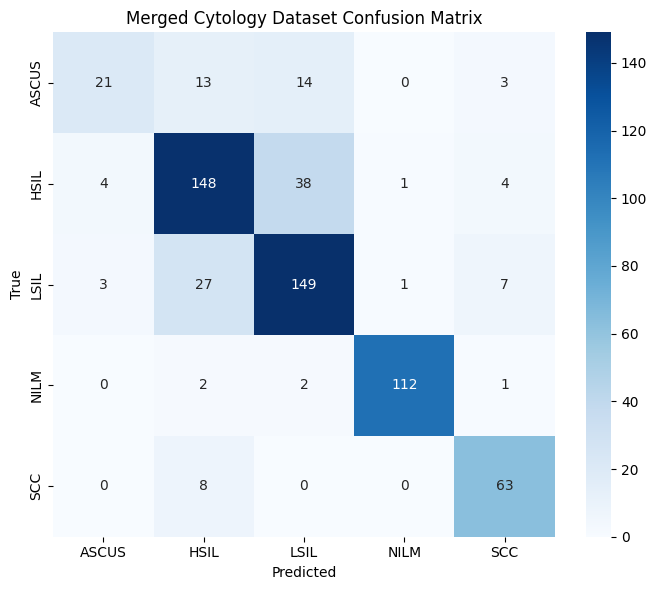

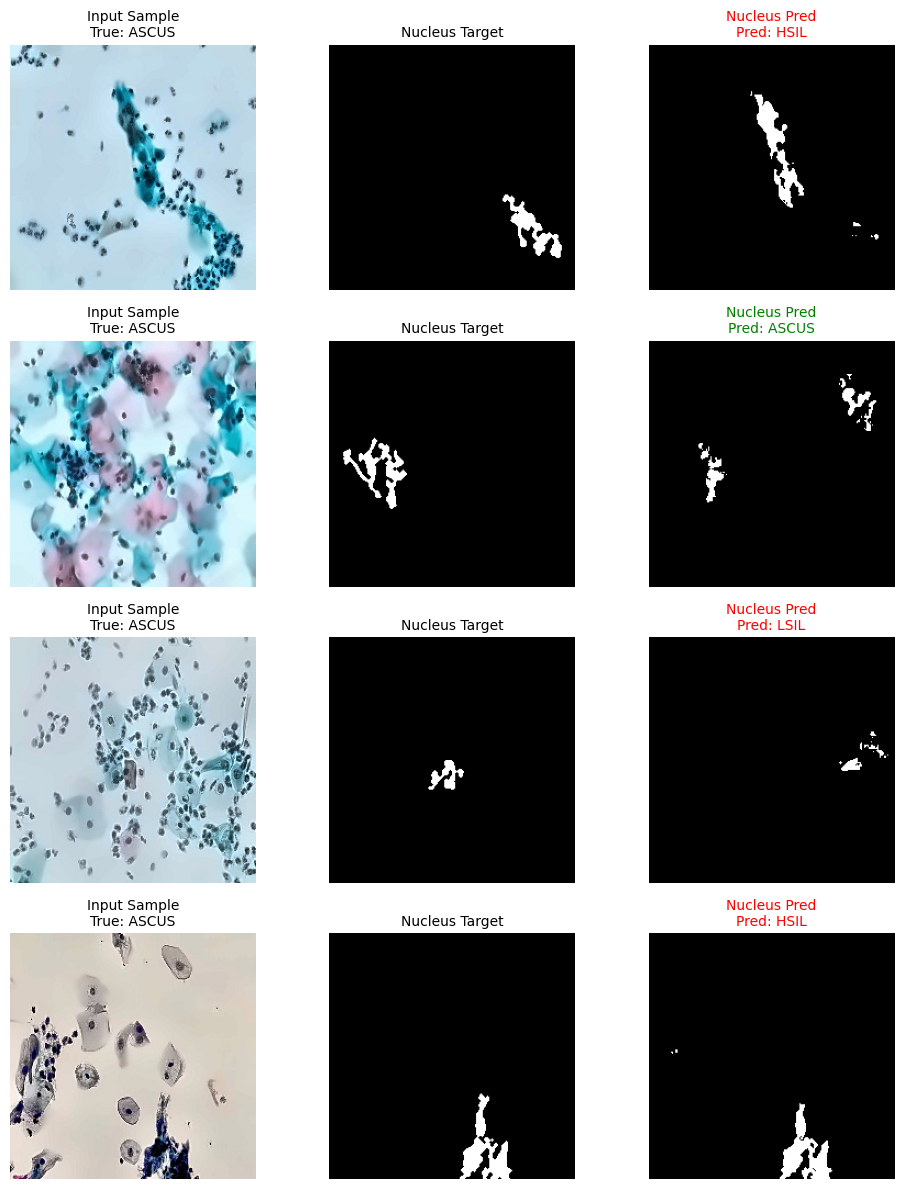

In [5]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_merged_multitask_data"
PLOTS_DIR = "plots_cytology_merged"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Samples)
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, non-local means denoising, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Edge-preserving noise reduction using non-local means filtering
    # h=10, hColor=10 are standard parameters for mild noise reduction
    # 7 is the template window size, 21 is the search window size
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 5, 5, 7, 21)

    # 3. Controlled sharpening using unsharp masking to enhance boundaries
    blurred = cv2.GaussianBlur(denoised, (0, 0), 1.0)
    sharpened = cv2.addWeighted(denoised, 1.5, blurred, -0.5, 0)
    
    # Normalize back to [0.0, 1.0] range
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """Extracts high-contrast nucleus masks via adaptive thresholding and morphological filtering."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Discovery, Harmonization & Merged Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

ENHANCED_DATA_DIR = "/kaggle/input/datasets/fahmidaifty/apcem-cervical-cytology-dataset/Enhanced Cervical Cytology Image dataset"
RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer"

all_records = []  # List of tuples: (image_path, class_name, needs_apcem)

# Collect from Dataset 1 (Enhanced - No APCEM needed)
if os.path.exists(ENHANCED_DATA_DIR):
    ds1_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(ENHANCED_DATA_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, False))
                    ds1_count += 1
    print(f"Loaded {ds1_count} pre-enhanced images from Dataset 1.")
else:
    print(f"Warning: Dataset 1 path not found: {ENHANCED_DATA_DIR}")

# Collect from Dataset 2 (Raw - APCEM will be applied)
if os.path.exists(RAW_DATA_DIR):
    ds2_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(RAW_DATA_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, True))
                    ds2_count += 1
    print(f"Loaded {ds2_count} raw images from Dataset 2.")
else:
    print(f"Warning: Dataset 2 path not found: {RAW_DATA_DIR}")

if len(all_records) == 0:
    raise RuntimeError("No images found across both datasets.")

print(f"\nTotal merged records: {len(all_records)} across Bethesda classes: {BETHESDA_CLASSES}")

# Unified Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Processing and saving {len(recs)} samples for '{split_name}' split...")
    for idx, (img_path, cls_name, apply_apcem) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        if apply_apcem:
            img_enhanced = apcem_preprocess(img_resized)
            img_final_uint8 = (img_enhanced * 255.0).astype(np.uint8)
        else:
            img_final_uint8 = img_resized

        # Extract high-contrast nucleus mask
        mask = extract_nucleus_mask(img_final_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{split_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_final_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nMerged dataset preparation and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.split("_")[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    """Residual Conv-BN-ReLU x2 block. A 1x1 shortcut matches channels
    when in_ch != out_ch so the identity can always be added back."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.shortcut = (
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch))
            if in_ch != out_ch else nn.Identity()
        )

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))

class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder (residual DoubleConv blocks)
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128), nn.Dropout2d(0.15))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256), nn.Dropout2d(0.20))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch: combine average + max pooled features
        # (max-pool helps pick up localized chromatin/texture cues that
        # matter for distinguishing ASCUS/LSIL/HSIL, which GAP alone can dilute)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.gmp = nn.AdaptiveMaxPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256 * 2, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits (avg-pooled + max-pooled features concatenated)
        pooled = torch.cat([self.gap(feat).flatten(1), self.gmp(feat).flatten(1)], dim=1)
        cls_logits = self.classifier(pooled)

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)

        return seg_logits, cls_logits     



# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Merged Cytology Dataset (1+2)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_merged_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nRestored optimal model weights from validation loss checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Multi-Task Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_merged_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Merged Cytology Dataset Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_merged_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input Sample\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_merged_sample_inference.png", dpi=200)
plt.show()

# **Merged Cytology Dataset 1 + 2 (Using Model 1)**

Using compute device: cuda
Loaded 4134 pre-enhanced images from Dataset 1.
Loaded 0 raw images from Dataset 2.

Total merged records: 4134 across Bethesda classes: ['ASCUS', 'HSIL', 'LSIL', 'NILM', 'SCC']
Processing and saving 2893 samples for 'train' split...
Processing and saving 620 samples for 'val' split...
Processing and saving 621 samples for 'test' split...

Merged dataset preparation and nucleus mask extraction complete.

Starting joint training on Merged Cytology Dataset (1+2)...
Epoch 01/50 | Train Loss: 2.3738 Acc: 0.429 Dice: 0.267 | Val Loss: 2.7141 Acc: 0.248 Dice: 0.278
Epoch 02/50 | Train Loss: 2.0831 Acc: 0.485 Dice: 0.290 | Val Loss: 2.4461 Acc: 0.350 Dice: 0.307
Epoch 03/50 | Train Loss: 2.0072 Acc: 0.490 Dice: 0.306 | Val Loss: 2.4317 Acc: 0.419 Dice: 0.311
Epoch 04/50 | Train Loss: 2.0157 Acc: 0.480 Dice: 0.310 | Val Loss: 1.8850 Acc: 0.515 Dice: 0.333
Epoch 05/50 | Train Loss: 1.9828 Acc: 0.464 Dice: 0.318 | Val Loss: 2.1232 Acc: 0.411 Dice: 0.320
Epoch 06/50 | T

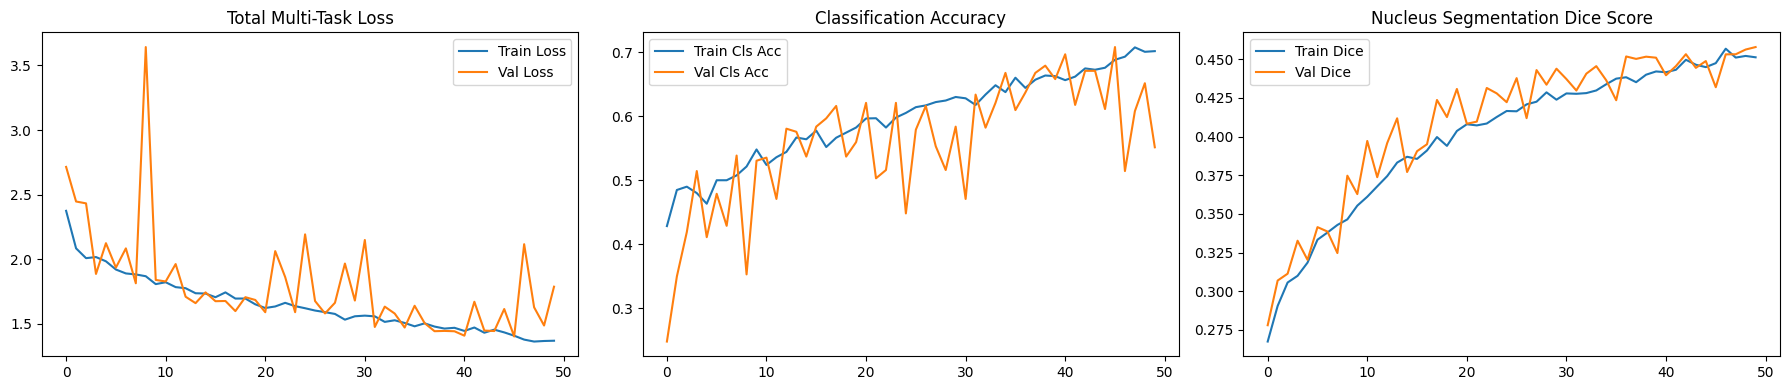


Final Test Classification Accuracy: 0.7134
Final Test Nucleus Segmentation Mean Dice Score: 0.3946

Classification Report:
              precision    recall  f1-score   support

       ASCUS       0.50      0.14      0.22        51
        HSIL       0.63      0.72      0.67       195
        LSIL       0.68      0.72      0.70       187
        NILM       0.90      0.95      0.92       117
         SCC       0.80      0.69      0.74        71

    accuracy                           0.71       621
   macro avg       0.70      0.64      0.65       621
weighted avg       0.70      0.71      0.70       621



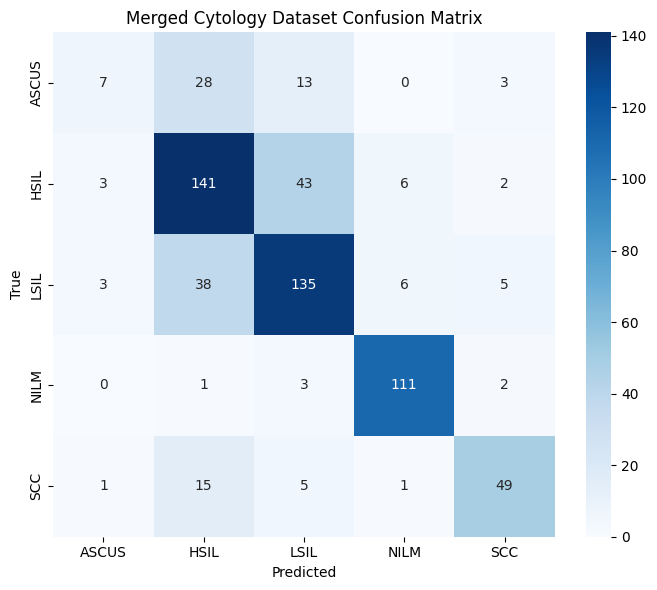

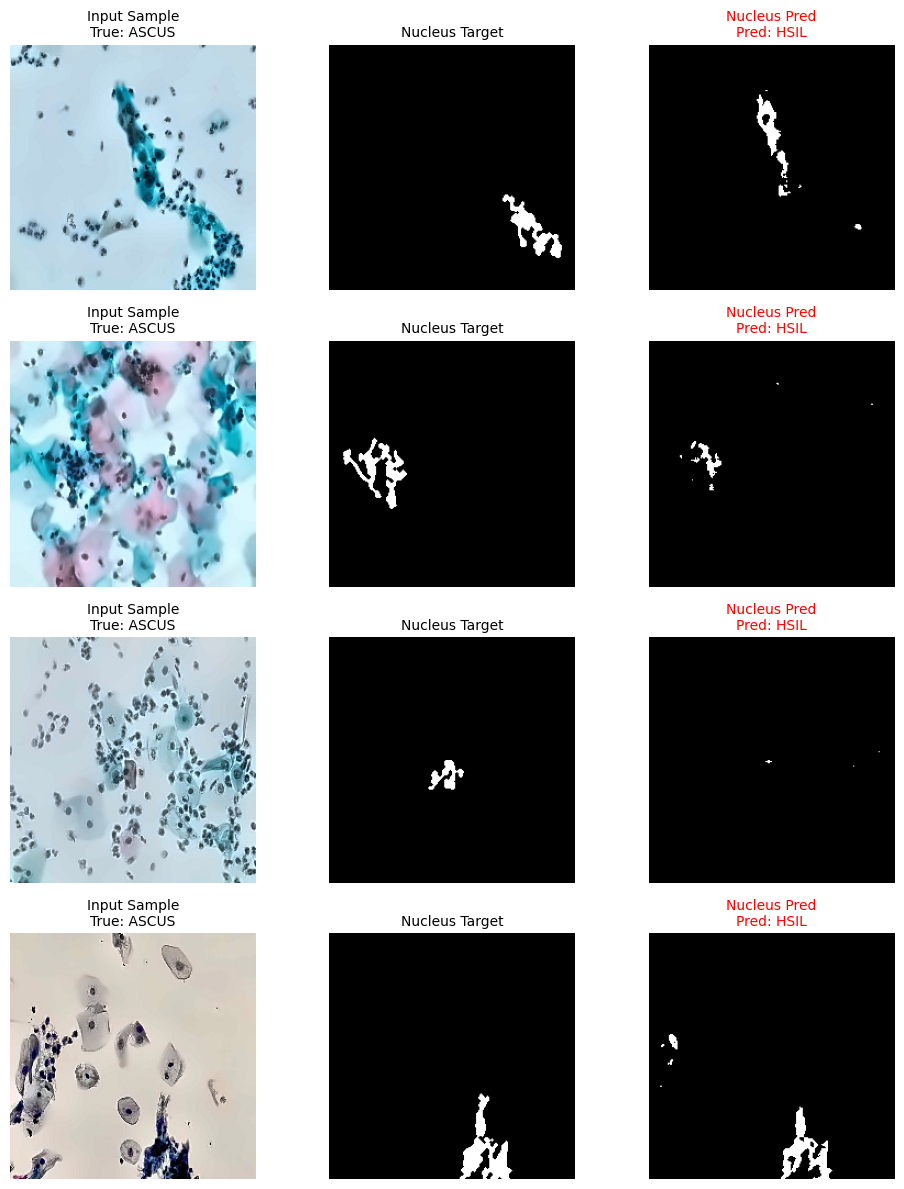

In [6]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------------------------------------------------
# 0. Global Setup & Reproducibility
# ---------------------------------------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
OUTPUT_DIR = "cytology_merged_multitask_data"
PLOTS_DIR = "plots_cytology_merged"

os.makedirs(PLOTS_DIR, exist_ok=True)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")


# ---------------------------------------------------------
# 1. APCEM Enhancement Function (For Raw Samples)
# ---------------------------------------------------------
def apcem_preprocess(image):
    """Enhance raw cytology images with CLAHE, non-local means denoising, and sharpening."""
    img = image.astype(np.float32)

    if img.max() <= 1.0:
        img = img * 255.0

    img_uint8 = np.clip(img, 0, 255).astype(np.uint8)

    # 1. CLAHE Contrast enhancement in LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 2. Edge-preserving noise reduction using non-local means filtering
    # h=10, hColor=10 are standard parameters for mild noise reduction
    # 7 is the template window size, 21 is the search window size
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 5, 5, 7, 21)

    # 3. Controlled sharpening using unsharp masking to enhance boundaries
    blurred = cv2.GaussianBlur(denoised, (0, 0), 1.0)
    sharpened = cv2.addWeighted(denoised, 1.5, blurred, -0.5, 0)
    
    # Normalize back to [0.0, 1.0] range
    enhanced = np.clip(sharpened.astype(np.float32) / 255.0, 0.0, 1.0)

    return enhanced


# ---------------------------------------------------------
# 2. Automated Nucleus Mask Extractor
# ---------------------------------------------------------
def extract_nucleus_mask(img_rgb):
    """Extracts high-contrast nucleus masks via adaptive thresholding and morphological filtering."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 5
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    nucleus_mask = np.zeros_like(gray, dtype=np.uint8)

    if contours:
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        cv2.drawContours(nucleus_mask, [contours[0]], -1, 255, -1)
    else:
        nucleus_mask = clean_mask

    return nucleus_mask


# ---------------------------------------------------------
# 3. Discovery, Harmonization & Merged Stratified Split
# ---------------------------------------------------------
BETHESDA_CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]

ENHANCED_DATA_DIR = "/kaggle/input/datasets/fahmidaifty/apcem-cervical-cytology-dataset/Enhanced Cervical Cytology Image dataset"
RAW_DATA_DIR = "/kaggle/input/datasets/jxxn03x/cytologcervicalcancer"

all_records = []  # List of tuples: (image_path, class_name, needs_apcem)

# Collect from Dataset 1 (Enhanced - No APCEM needed)
if os.path.exists(ENHANCED_DATA_DIR):
    ds1_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(ENHANCED_DATA_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, False))
                    ds1_count += 1
    print(f"Loaded {ds1_count} pre-enhanced images from Dataset 1.")
else:
    print(f"Warning: Dataset 1 path not found: {ENHANCED_DATA_DIR}")

# Collect from Dataset 2 (Raw - APCEM will be applied)
if os.path.exists(RAW_DATA_DIR):
    ds2_count = 0
    for cls in BETHESDA_CLASSES:
        cls_dir = os.path.join(RAW_DATA_DIR, cls)
        if os.path.exists(cls_dir):
            for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.PNG"):
                for img_path in glob.glob(os.path.join(cls_dir, ext)):
                    all_records.append((img_path, cls, True))
                    ds2_count += 1
    print(f"Loaded {ds2_count} raw images from Dataset 2.")
else:
    print(f"Warning: Dataset 2 path not found: {RAW_DATA_DIR}")

if len(all_records) == 0:
    raise RuntimeError("No images found across both datasets.")

print(f"\nTotal merged records: {len(all_records)} across Bethesda classes: {BETHESDA_CLASSES}")

# Unified Stratified 70% Train, 15% Val, 15% Test Split
labels = [r[1] for r in all_records]
train_rec, temp_rec = train_test_split(all_records, test_size=0.30, stratify=labels, random_state=SEED)
temp_labels = [r[1] for r in temp_rec]
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, stratify=temp_labels, random_state=SEED)

splits = {"train": train_rec, "val": val_rec, "test": test_rec}

for split_name, recs in splits.items():
    images_dir = os.path.join(OUTPUT_DIR, split_name, "images")
    masks_dir = os.path.join(OUTPUT_DIR, split_name, "masks_nuc")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(masks_dir, exist_ok=True)

    print(f"Processing and saving {len(recs)} samples for '{split_name}' split...")
    for idx, (img_path, cls_name, apply_apcem) in enumerate(recs):
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMG_SIZE, interpolation=cv2.INTER_LINEAR)

        if apply_apcem:
            img_enhanced = apcem_preprocess(img_resized)
            img_final_uint8 = (img_enhanced * 255.0).astype(np.uint8)
        else:
            img_final_uint8 = img_resized

        # Extract high-contrast nucleus mask
        mask = extract_nucleus_mask(img_final_uint8)
        mask_resized = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        file_prefix = f"{cls_name}_{split_name}_{idx:05d}.png"
        cv2.imwrite(os.path.join(images_dir, file_prefix), cv2.cvtColor(img_final_uint8, cv2.COLOR_RGB2BGR))
        cv2.imwrite(os.path.join(masks_dir, file_prefix), mask_resized)

print("\nMerged dataset preparation and nucleus mask extraction complete.")


# ---------------------------------------------------------
# 4. PyTorch Dataset & DataLoader
# ---------------------------------------------------------
class CytologyMultiTaskDataset(Dataset):
    def __init__(self, data_root, split="train", class_names=BETHESDA_CLASSES):
        self.images_dir = Path(data_root) / split / "images"
        self.masks_dir = Path(data_root) / split / "masks_nuc"
        self.class_names = class_names
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []

        for img_path in sorted(self.images_dir.glob("*.png")):
            mask_path = self.masks_dir / img_path.name
            if mask_path.exists():
                cls_name = img_path.name.split("_")[0]
                self.samples.append((str(img_path), str(mask_path), self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = img.transpose(2, 0, 1)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = np.expand_dims((mask > 0.5).astype(np.float32), axis=0)

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(mask).float(),
            torch.tensor(label, dtype=torch.long)
        )


train_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "train")
val_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "val")
test_ds = CytologyMultiTaskDataset(OUTPUT_DIR, "test")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# ---------------------------------------------------------
# 5. Multi-Task Residual-Attention Network
# ---------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class AttentionBottleneck(nn.Module):
    def __init__(self, channels=256, heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        flat = x.permute(0, 2, 3, 1).reshape(b, h * w, c)
        flat = self.norm(flat)
        attn_out, _ = self.attn(flat, flat, flat)
        attn_out = attn_out.reshape(b, h, w, c).permute(0, 3, 1, 2)
        return F.relu(x + self.proj(attn_out))


class MultiTaskCytologyNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(3, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        # Self-Attention Bottleneck
        self.bottleneck_attn = AttentionBottleneck(256)

        # Segmentation Decoder Branch
        self.up1 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv_up2 = DoubleConv(128, 64)

        self.up3 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv_up3 = DoubleConv(64, 32)

        self.seg_out = nn.Conv2d(32, 1, 1)

        # Classification Branch
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        feat = self.bottleneck_attn(x4)

        # Classification logits
        cls_logits = self.classifier(self.gap(feat).flatten(1))

        # Segmentation mask logits
        d1 = self.up1(feat)
        d1 = self.conv_up1(torch.cat([d1, x3], dim=1))

        d2 = self.up2(d1)
        d2 = self.conv_up2(torch.cat([d2, x2], dim=1))

        d3 = self.up3(d2)
        d3 = self.conv_up3(torch.cat([d3, x1], dim=1))

        seg_logits = self.seg_out(d3)
        return seg_logits, cls_logits



# ---------------------------------------------------------
# 6. Losses, Metrics & Training Setup
# ---------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice


def compute_dice_score(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + 1e-6) / (preds.sum() + targets.sum() + 1e-6)
    return dice.item()


model = MultiTaskCytologyNet(num_classes=len(BETHESDA_CLASSES)).to(device)
bce_loss_fn = nn.BCEWithLogitsLoss()
dice_loss_fn = DiceLoss()
cls_loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=5)


# ---------------------------------------------------------
# 7. Training & Validation Loop
# ---------------------------------------------------------
best_val_loss = float("inf")
best_state = None
history = {"train_loss": [], "val_loss": [], "cls_acc": [], "val_cls_acc": [], "dice": [], "val_dice": []}

print(f"\nStarting joint training on Merged Cytology Dataset (1+2)...")

for epoch in range(NUM_EPOCHS):
    model.train()
    t_loss, t_correct, t_total, t_dice = 0.0, 0, 0, 0.0

    for imgs, masks, labels in train_loader:
        imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)

        optimizer.zero_grad()
        seg_logits, cls_logits = model(imgs)

        l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
        l_cls = cls_loss_fn(cls_logits, labels)
        total_loss = l_seg + 1.0 * l_cls

        total_loss.backward()
        optimizer.step()

        t_loss += total_loss.item() * imgs.size(0)
        t_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
        t_total += labels.size(0)
        t_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    train_loss = t_loss / t_total
    train_acc = t_correct / t_total
    train_dice = t_dice / t_total

    model.eval()
    v_loss, v_correct, v_total, v_dice = 0.0, 0, 0, 0.0

    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(device), masks.to(device), labels.to(device)
            seg_logits, cls_logits = model(imgs)

            l_seg = bce_loss_fn(seg_logits, masks) + dice_loss_fn(seg_logits, masks)
            l_cls = cls_loss_fn(cls_logits, labels)
            total_loss = l_seg + 1.0 * l_cls

            v_loss += total_loss.item() * imgs.size(0)
            v_correct += (cls_logits.argmax(dim=1) == labels).sum().item()
            v_total += labels.size(0)
            v_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

    val_loss = v_loss / v_total
    val_acc = v_correct / v_total
    val_dice = v_dice / v_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["cls_acc"].append(train_acc)
    history["val_cls_acc"].append(val_acc)
    history["dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.3f} Dice: {train_dice:.3f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} Dice: {val_dice:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_cytology_merged_multitask_model.pth")

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nRestored optimal model weights from validation loss checkpoint.")


# ---------------------------------------------------------
# 8. Evaluation & Qualitative Visualization
# ---------------------------------------------------------
model.eval()

# 1. Multi-Task Training Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Total Multi-Task Loss")
axes[0].legend()

axes[1].plot(history["cls_acc"], label="Train Cls Acc")
axes[1].plot(history["val_cls_acc"], label="Val Cls Acc")
axes[1].set_title("Classification Accuracy")
axes[1].legend()

axes[2].plot(history["dice"], label="Train Dice")
axes[2].plot(history["val_dice"], label="Val Dice")
axes[2].set_title("Nucleus Segmentation Dice Score")
axes[2].legend()

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_merged_training_curves.png", dpi=200)
plt.show()

# 2. Test Set Multi-Task Evaluation
all_true, all_pred, total_test_dice = [], [], 0.0
with torch.no_grad():
    for imgs, masks, labels in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        seg_logits, cls_logits = model(imgs)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(cls_logits.argmax(dim=1).cpu().numpy().tolist())
        total_test_dice += compute_dice_score(seg_logits, masks) * imgs.size(0)

test_acc = accuracy_score(all_true, all_pred)
mean_test_dice = total_test_dice / len(test_ds)
print(f"\nFinal Test Classification Accuracy: {test_acc:.4f}")
print(f"Final Test Nucleus Segmentation Mean Dice Score: {mean_test_dice:.4f}")

print("\nClassification Report:")
print(classification_report(all_true, all_pred, target_names=BETHESDA_CLASSES, zero_division=0))

# 3. Confusion Matrix
cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=BETHESDA_CLASSES, yticklabels=BETHESDA_CLASSES)
plt.title("Merged Cytology Dataset Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/cytology_merged_confusion_matrix.png", dpi=200)
plt.show()

# 4. Sample Test Predictions Visualization
sample_imgs, sample_masks, sample_labels = next(iter(test_loader))
with torch.no_grad():
    s_seg_logits, s_cls_logits = model(sample_imgs.to(device))
    s_seg_preds = (torch.sigmoid(s_seg_logits) > 0.5).float().cpu().numpy()
    s_cls_preds = s_cls_logits.argmax(dim=1).cpu().numpy()

s_imgs_np = sample_imgs.permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for i in range(min(4, len(s_imgs_np))):
    t_cls = BETHESDA_CLASSES[sample_labels[i].item()]
    p_cls = BETHESDA_CLASSES[s_cls_preds[i]]

    axes[i, 0].imshow(np.clip(s_imgs_np[i], 0, 1))
    axes[i, 0].set_title(f"Input Sample\nTrue: {t_cls}", fontsize=10)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sample_masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Nucleus Target", fontsize=10)
    axes[i, 1].axis("off")

    axes[i, 2].imshow(s_seg_preds[i, 0], cmap="gray")
    axes[i, 2].set_title(f"Nucleus Pred\nPred: {p_cls}", color="green" if t_cls == p_cls else "red", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
fig.savefig(f"{PLOTS_DIR}/cytology_merged_sample_inference.png", dpi=200)
plt.show()